# Previsão da cota do Rio Taquari com redes neurais

**Projeto acadêmico de regressão supervisionada** — estimar a cota de amanhã usando observações diárias da estação ANA 86720000 (Encantado) e chuva da estação 2951010. O notebook audita os CSVs, constrói janelas temporais sem atravessar lacunas, compara baselines e MLPs e avalia o modelo escolhido em um bloco temporal futuro.

Este estudo é retrospectivo e não é um sistema de alerta. Cota de rio não representa armazenamento de reservatório. Os dados brutos são mantidos em `dados/`; saídas reproduzíveis são escritas em `resultados/`.


## 1. Ambiente e caminhos

Execute as células em ordem. O notebook procura a pasta do projeto a partir do diretório corrente ou do próprio arquivo. Os pacotes necessários estão listados em `requirements.txt`.


In [1]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEMENTE = 42
np.random.seed(SEMENTE)

def localizar_projeto():
    candidatos = [Path.cwd(), Path.cwd().parent]
    try:
        candidatos += [Path(__file__).resolve().parents[1]]
    except NameError:
        pass
    for pasta in candidatos:
        if (pasta / "dados").is_dir() and (pasta / "notebooks").is_dir():
            return pasta.resolve()
    raise FileNotFoundError("Abra o projeto ou execute o notebook a partir da pasta RedesNeurais_ANA.")

RAIZ = localizar_projeto()
DIR_DADOS = RAIZ / "dados"
DIR_RESULTADOS = RAIZ / "resultados"
DIR_RESULTADOS.mkdir(exist_ok=True)
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")
print(f"Projeto: {RAIZ}")


Python 3.13.5 | pandas 2.3.3 | scikit-learn 1.9.1
Projeto: C:\Users\PedroMenezes\Documents\EngenhariaDeComputacao\DeepLearning\RedesNeurais_ANA


## 2. Leitura e auditoria dos arquivos ANA

As exportações contêm metadados e linhas em branco antes do cabeçalho. A leitura usa `skiprows` com o índice físico do cabeçalho; isso evita que linhas em branco alterem a interpretação de `header`. Os valores são inicialmente strings para preservar a vírgula decimal e distinguir vazios de zero.


In [2]:
ARQUIVOS = {
    "Cota": DIR_DADOS / "86720000_Cotas.csv",
    "Vazao": DIR_DADOS / "86720000_Vazoes.csv",
    "Chuva": DIR_DADOS / "2951010_Chuvas.csv",
}

def ler_exportacao_ana(caminho):
    if not caminho.is_file():
        raise FileNotFoundError(f"Arquivo obrigatório ausente: {caminho}")
    conteudo = caminho.read_bytes()
    texto = None
    codificacao = None
    for candidata in ("utf-8-sig", "cp1252", "latin1"):
        try:
            texto = conteudo.decode(candidata)
            codificacao = candidata
            break
        except UnicodeDecodeError:
            continue
    linhas = texto.splitlines()
    indice = next((i for i, linha in enumerate(linhas)
                   if linha.lstrip("\ufeff").startswith("EstacaoCodigo;")), None)
    if indice is None:
        raise ValueError(f"Cabeçalho EstacaoCodigo não encontrado em {caminho.name}")
    # skiprows conta linhas físicas, inclusive as linhas em branco anteriores.
    tabela = pd.read_csv(caminho, sep=";", encoding=codificacao,
                         skiprows=indice, dtype="string", skipinitialspace=True)
    tabela.columns = tabela.columns.str.strip()
    return tabela, codificacao, indice + 1

brutos = {}
auditoria_arquivos = []
for nome, caminho in ARQUIVOS.items():
    tabela, codificacao, linha_cabecalho = ler_exportacao_ana(caminho)
    brutos[nome] = tabela
    coluna_valor = {"Cota": "Cota01", "Vazao": "Vazao01", "Chuva": "Chuva01"}[nome]
    if "Data" not in tabela or coluna_valor not in tabela:
        raise ValueError(f"Esquema inesperado em {caminho.name}; confira cabeçalho e colunas.")
    datas_validas = pd.to_datetime(tabela["Data"], dayfirst=True, errors="coerce")
    auditoria_arquivos.append({
        "Série": nome, "Arquivo": caminho.name, "Codificação": codificacao,
        "Linha do cabeçalho": linha_cabecalho, "Linhas mensais": len(tabela),
        "Colunas": len(tabela.columns), "Primeira data": datas_validas.min(),
        "Última data": datas_validas.max(),
    })
display(pd.DataFrame(auditoria_arquivos))
print("\nExemplo de registros mensais de cota:")
display(brutos["Cota"].head(3))



Exemplo de registros mensais de cota:


,Série,Arquivo,Codificação,Linha do cabeçalho,Linhas mensais,Colunas,Primeira data,Última data
0,Cota,86720000_Cotas.csv,cp1252,16,2087,78,1941-10-01,2026-04-01
1,Vazao,86720000_Vazoes.csv,cp1252,16,1012,78,1941-10-01,2026-04-01
2,Chuva,2951010_Chuvas.csv,cp1252,15,1701,75,1943-04-01,2026-04-01


,EstacaoCodigo,NivelConsistencia,Data,hora,MediaDiaria,TipoMedicaoCotas,Maxima,Minima,Media,DiaMaxima,DiaMinima,MaximaStatus,MinimaStatus,MediaStatus,MediaAnual,MediaAnualStatus,Cota01,Cota02,Cota03,Cota04,Cota05,Cota06,Cota07,Cota08,Cota09,Cota10,Cota11,Cota12,Cota13,Cota14,Cota15,Cota16,Cota17,Cota18,Cota19,Cota20,Cota21,Cota22,Cota23,Cota24,Cota25,Cota26,Cota27,Cota28,Cota29,Cota30,Cota31,Cota01Status,Cota02Status,Cota03Status,Cota04Status,Cota05Status,Cota06Status,Cota07Status,Cota08Status,Cota09Status,Cota10Status,Cota11Status,Cota12Status,Cota13Status,Cota14Status,Cota15Status,Cota16Status,Cota17Status,Cota18Status,Cota19Status,Cota20Status,Cota21Status,Cota22Status,Cota23Status,Cota24Status,Cota25Status,Cota26Status,Cota27Status,Cota28Status,Cota29Status,Cota30Status,Cota31Status
0,86720000,1,01/04/2026,07:00,0,1,83,10,20,13,19,0,0,0,<NA>,0,11,11,12,13,12,11,26,11,11,39,11,11,11,24,16,28,11,11,10,10,11,11,11,11,11,11,21,10,10,49,<NA>,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0
1,86720000,1,01/04/2026,17:00,0,1,83,10,20,13,19,0,0,0,<NA>,0,25,16,30,32,26,14,28,20,54,48,13,18,83,33,12,29,15,23,24,12,11,13,24,11,11,21,30,17,11,18,<NA>,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0
2,86720000,1,01/04/2026,<NA>,1,1,83,10,20,13,19,0,0,0,<NA>,0,18,14,21,23,19,13,27,16,33,44,12,15,47,29,14,29,13,17,17,11,11,12,18,11,11,16,26,14,11,34,<NA>,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0


## 3. Expansão diária e regra de qualidade

Cada linha mensal é expandida para dias reais do calendário; datas impossíveis e valores ausentes não viram observações. Entram no conjunto analisável apenas medições com status diário `1` (real). Para cotas e vazões, também se exige `MediaDiaria = 1`, evitando misturar leituras instantâneas com médias diárias. Entre duplicatas elegíveis, prioriza-se `NivelConsistencia = 2`; se ainda houver mais de uma medição igualmente elegível no dia, usa-se a mediana e registra-se a colisão. A unidade da cota não é indicada nesses CSVs, portanto os resultados preservam a unidade reportada sem rotulá-la como cm.


In [3]:
def para_numero(serie):
    return pd.to_numeric(serie.astype("string").str.strip().str.replace(",", ".", regex=False), errors="coerce")

def expandir_diario(nome, tabela):
    prefixo = {"Cota": "Cota", "Vazao": "Vazao", "Chuva": "Chuva"}[nome]
    colunas_dia = [f"{prefixo}{dia:02d}" for dia in range(1, 32) if f"{prefixo}{dia:02d}" in tabela]
    if not colunas_dia:
        raise ValueError(f"Nenhuma coluna diária {prefixo}01..{prefixo}31 em {nome}.")
    mensal = tabela.copy()
    mensal["Data"] = pd.to_datetime(mensal["Data"], dayfirst=True, errors="coerce")
    mensal["NivelConsistencia"] = para_numero(mensal["NivelConsistencia"])
    if nome in ("Cota", "Vazao"):
        mensal["MediaDiaria"] = para_numero(mensal["MediaDiaria"])
        mensal = mensal[mensal["MediaDiaria"].eq(1)]
    registros = []
    for coluna in colunas_dia:
        dia = int(coluna[-2:])
        status_coluna = f"{coluna}Status"
        mes = mensal["Data"]
        data_dia = mes + pd.to_timedelta(dia - 1, unit="D")
        valido_no_mes = data_dia.dt.month.eq(mes.dt.month)
        bloco = pd.DataFrame({
            "Data": data_dia,
            "Valor": para_numero(mensal[coluna]),
            "Status": mensal[status_coluna].astype("string").str.strip() if status_coluna in mensal else pd.NA,
            "Consistencia": mensal["NivelConsistencia"],
        })
        registros.append(bloco.loc[valido_no_mes])
    longo = pd.concat(registros, ignore_index=True).dropna(subset=["Data", "Valor"])
    elegivel = longo[longo["Status"].eq("1") & longo["Valor"].map(np.isfinite)].copy()
    contagem_por_data = elegivel.groupby("Data").size()
    dias_com_colisao = int(contagem_por_data.gt(1).sum())
    if elegivel.empty:
        raise ValueError(f"Nenhuma observação elegível para {nome} após regra de status.")
    elegivel = elegivel.sort_values(["Data", "Consistencia"], ascending=[True, False])
    melhor_nivel = elegivel.groupby("Data")["Consistencia"].transform("max")
    elegivel = elegivel[elegivel["Consistencia"].eq(melhor_nivel)]
    diaria = elegivel.groupby("Data")["Valor"].median().sort_index().rename(nome)
    resumo = {
        "Série": nome, "Candidatas diárias com valor": len(longo),
        "Observações reais elegíveis": len(elegivel), "Dias após desempate": len(diaria),
        "Dias com duplicatas elegíveis": dias_com_colisao,
        "Registros excluídos por status": int(len(longo) - len(elegivel)),
        "Primeiro dia": diaria.index.min(), "Último dia": diaria.index.max(),
        "Lacunas entre observações": int((diaria.index.to_series().diff().dt.days > 1).sum()),
    }
    return diaria, resumo, longo

series = {}
resumos_diarios = []
dados_longos = {}
for nome, tabela in brutos.items():
    series[nome], resumo, dados_longos[nome] = expandir_diario(nome, tabela)
    resumos_diarios.append(resumo)
display(pd.DataFrame(resumos_diarios))


,Série,Candidatas diárias com valor,Observações reais elegíveis,Dias após desempate,Dias com duplicatas elegíveis,Registros excluídos por status,Primeiro dia,Último dia,Lacunas entre observações
0,Cota,46153,21193,21193,15595,24960,1941-10-15,2026-04-30,236
1,Vazao,24619,20103,20103,0,4516,1941-10-15,2026-04-30,250
2,Chuva,51261,28844,28844,22338,22417,1943-04-19,2026-04-30,71


## 4. Alinhamento temporal e análise exploratória

As séries são unidas pela data, sem interpolação. A base integrada mantém vazão para inspeção, mas ela não entra no modelo principal porque pode ser derivada da cota. A chuva vem de outra estação e pode não representar toda a bacia. Nenhuma análise de associação será tratada como causalidade.


Cobertura por série:
Datas com observação elegível nas três séries: 18,585

Estatísticas da base diária alinhada (sem preencher lacunas):


,Série,Dias observados,Início,Fim
0,Cota,21193,1941-10-15,2026-04-30
1,Vazao,20103,1941-10-15,2026-04-30
2,Chuva,28844,1943-04-19,2026-04-30


,count,mean,std,min,25%,50%,75%,max
Cota,21193.0,223.712735,155.08516,-4.0,132.0,187.0,259.0,2227.0
Vazao,20103.0,484.314326,808.433086,10.7772,121.1884,238.4469,534.3196,14003.006
Chuva,28844.0,3.839464,10.384912,0.0,0.0,0.0,0.0,158.8


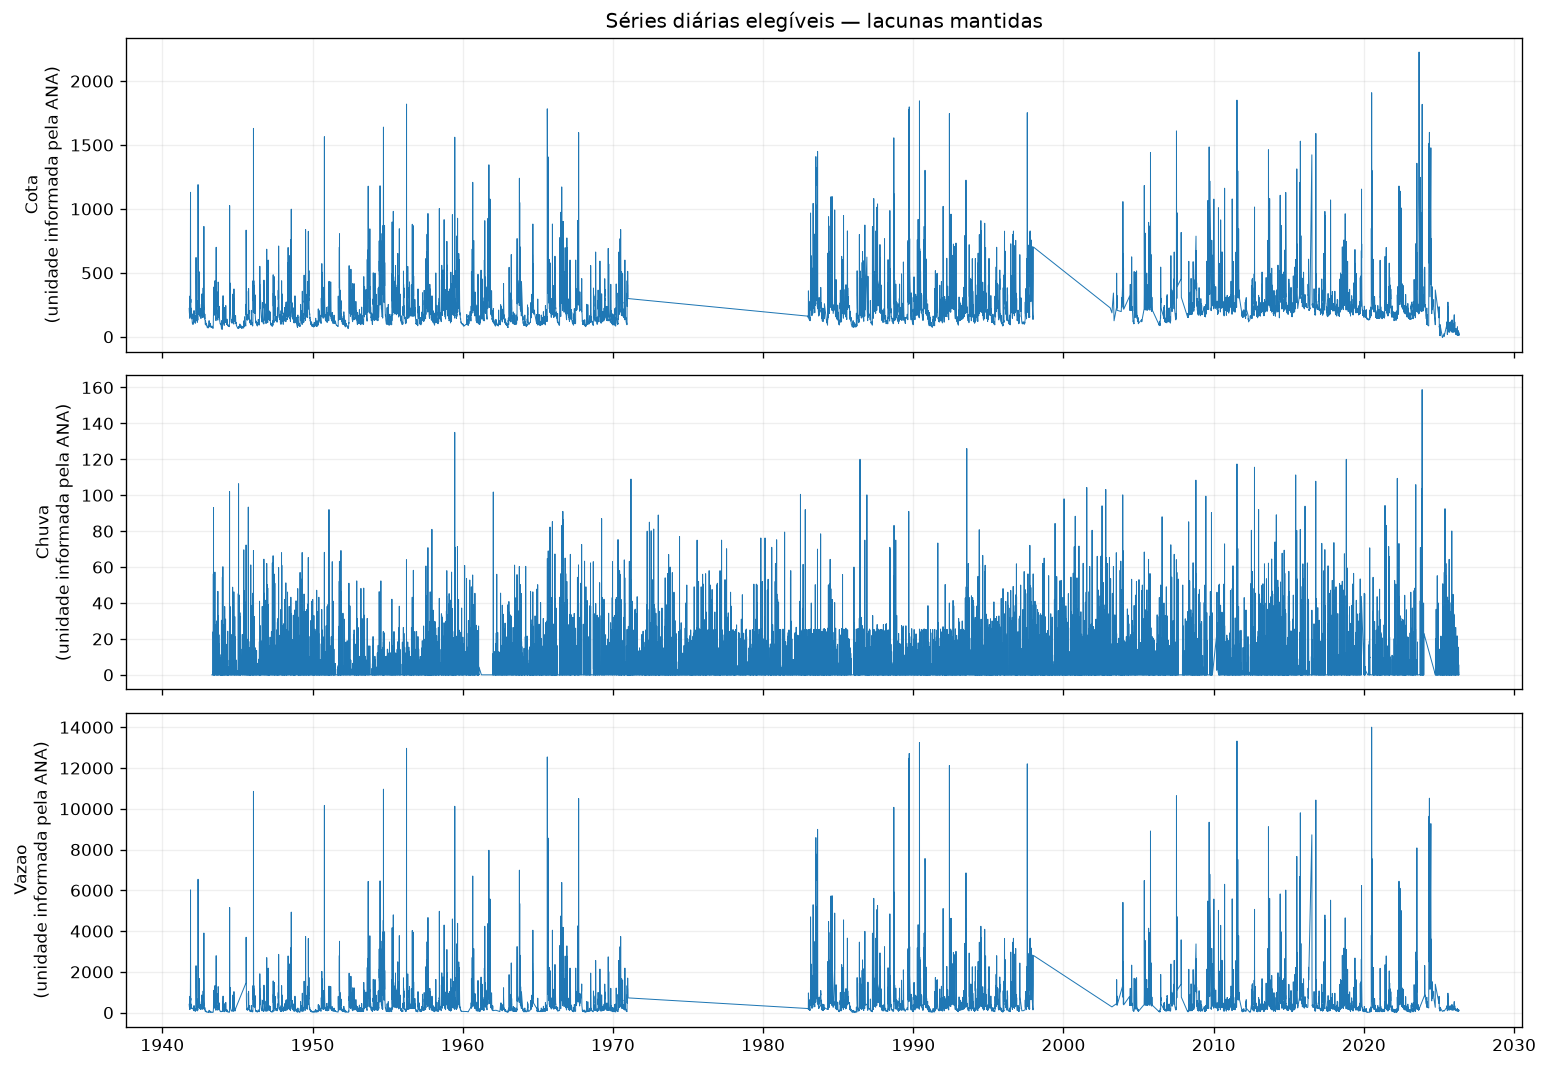

In [4]:
base = pd.concat(series.values(), axis=1).sort_index()
base.index.name = "Data"
base.to_csv(DIR_RESULTADOS / "series_diarias.csv", date_format="%Y-%m-%d")

resumo_cobertura = pd.DataFrame({
    "Série": list(series),
    "Dias observados": [len(s) for s in series.values()],
    "Início": [s.index.min() for s in series.values()],
    "Fim": [s.index.max() for s in series.values()],
})
datas_comuns = set(series["Cota"].index)
for nome in ("Chuva", "Vazao"):
    datas_comuns &= set(series[nome].index)
print("Cobertura por série:")
display(resumo_cobertura)
print(f"Datas com observação elegível nas três séries: {len(datas_comuns):,}")
print("\nEstatísticas da base diária alinhada (sem preencher lacunas):")
display(base.describe().T)

fig, eixos = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
for ax, nome, unidade in zip(eixos, ("Cota", "Chuva", "Vazao"), ("unidade informada pela ANA", "unidade informada pela ANA", "unidade informada pela ANA")):
    ax.plot(series[nome].index, series[nome].values, linewidth=0.6)
    ax.set_ylabel(f"{nome}\n({unidade})")
    ax.grid(alpha=0.2)
eixos[0].set_title("Séries diárias elegíveis — lacunas mantidas")
fig.tight_layout()
fig.savefig(DIR_RESULTADOS / "series_historicas.png", dpi=160, bbox_inches="tight")
plt.show()


## 5. Dataset supervisionado e cortes cronológicos

O instante de emissão é o fim do dia `t`: entram cotas e chuvas de `t-6` até `t`, e o alvo é a cota de `t+1`. Uma janela só é aceita se todos os oito dias (sete entradas mais o alvo) forem datas consecutivas e se todas as variáveis de entrada e alvo estiverem observadas. Os 20% mais recentes são reservados ao teste; os 80% anteriores formam o bloco de desenvolvimento, subdividido cronologicamente em 68% treino efetivo e 12% validação. Não há embaralhamento.


In [5]:
calendario = pd.date_range(base.index.min(), base.index.max(), freq="D", name="Data")
diaria = base.reindex(calendario)
supervisionado = pd.DataFrame(index=calendario)
for lag in range(6, -1, -1):
    supervisionado[f"cota_t_menos_{lag}"] = diaria["Cota"].shift(lag)
    supervisionado[f"chuva_t_menos_{lag}"] = diaria["Chuva"].shift(lag)
supervisionado["alvo_cota_t_mais_1"] = diaria["Cota"].shift(-1)
supervisionado["data_alvo"] = pd.Series(calendario, index=calendario).shift(-1)
supervisionado["cota_persistencia"] = diaria["Cota"]

colunas_modelo = [c for c in supervisionado if c.startswith(("cota_", "chuva_")) and c != "cota_persistencia"]
supervisionado = supervisionado.dropna(subset=colunas_modelo + ["alvo_cota_t_mais_1", "data_alvo", "cota_persistencia"])
supervisionado = supervisionado[supervisionado["data_alvo"] == supervisionado.index + pd.Timedelta(days=1)].copy()
assert (supervisionado["data_alvo"] - supervisionado.index).eq(pd.Timedelta(days=1)).all()
supervisionado.index.name = "data_referencia_t"
supervisionado.to_csv(DIR_RESULTADOS / "dataset_supervisionado.csv", date_format="%Y-%m-%d")

n = len(supervisionado)
if n < 100:
    raise ValueError(f"Apenas {n} janelas supervisionadas válidas; quantidade insuficiente para treino/validação/teste.")
n_desenvolvimento = int(n * 0.80)
n_teste = n - n_desenvolvimento
n_validacao = int(n_desenvolvimento * 0.15)
n_treino = n_desenvolvimento - n_validacao
treino = supervisionado.iloc[:n_treino]
validacao = supervisionado.iloc[n_treino:n_desenvolvimento]
teste = supervisionado.iloc[n_desenvolvimento:]
print(f"Janelas válidas: {n:,} | desenvolvimento: {n_desenvolvimento/n:.1%} (treino + validação) | teste: {n_teste/n:.1%}")
print(f"Dentro do desenvolvimento: treino {n_treino/n:.1%} e validação {n_validacao/n:.1%} do total")
display(pd.DataFrame([
    {"Conjunto": nome, "Amostras": len(df), "Data inicial": df.index.min(), "Data final da referência": df.index.max(), "Data final do alvo": df["data_alvo"].max()}
    for nome, df in (("Treino efetivo", treino), ("Validação", validacao), ("Desenvolvimento total", supervisionado.iloc[:n_desenvolvimento]), ("Teste", teste))
]))


Janelas válidas: 18,252 | desenvolvimento: 80.0% (treino + validação) | teste: 20.0%
Dentro do desenvolvimento: treino 68.0% e validação 12.0% do total


,Conjunto,Amostras,Data inicial,Data final da referência,Data final do alvo
0,Treino efetivo,12411,1943-04-25,1993-03-08,1993-03-09
1,Validação,2190,1993-03-09,2008-11-23,2008-11-24
2,Desenvolvimento total,14601,1943-04-25,2008-11-23,2008-11-24
3,Teste,3651,2008-11-24,2026-04-29,2026-04-30


## 6. Normalização, baselines e seleção de MLP

O `MinMaxScaler` das entradas e o scaler do alvo são ajustados somente no treino. O alvo é revertido para a unidade original antes das métricas. Valores de validação/teste podem ficar fora de `[0, 1]` quando excedem a faixa do treino; não se reajusta o scaler. A arquitetura é escolhida pela menor MAE de validação entre quatro MLPs: uma camada de 32 neurônios ou duas camadas (64, 32), cada uma com cota apenas ou cota + chuva. Early stopping usa apenas a validação.


In [6]:
import tensorflow as tf
from tensorflow import keras

tf.keras.utils.set_random_seed(SEMENTE)
try:
    tf.config.threading.set_intra_op_parallelism_threads(2)
    tf.config.threading.set_inter_op_parallelism_threads(2)
except RuntimeError:
    pass

features_cota = [f"cota_t_menos_{lag}" for lag in range(6, -1, -1)]
features_cota_chuva = features_cota + [f"chuva_t_menos_{lag}" for lag in range(6, -1, -1)]
y_coluna = "alvo_cota_t_mais_1"

scalers = {}
transformados = {}
for nome, features in (("Cota", features_cota), ("Cota + chuva", features_cota_chuva)):
    sx = MinMaxScaler()
    sy = MinMaxScaler()
    x_treino = sx.fit_transform(treino[features])
    y_treino = sy.fit_transform(treino[[y_coluna]])
    x_validacao = sx.transform(validacao[features])
    y_validacao = sy.transform(validacao[[y_coluna]])
    scalers[nome] = (sx, sy)
    transformados[nome] = (features, x_treino, y_treino, x_validacao, y_validacao)

def construir_mlp(n_entradas, unidades):
    camadas = [keras.layers.Input(shape=(n_entradas,))]
    camadas.extend(keras.layers.Dense(u, activation="relu") for u in unidades)
    camadas.append(keras.layers.Dense(1, activation="linear"))
    modelo = keras.Sequential(camadas)
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss=keras.losses.Huber())
    return modelo

candidatos = []
historicos = []
for nome_features, unidades, rotulo in (
    ("Cota", (32,), "MLP 32 — cota"),
    ("Cota", (64, 32), "MLP 64-32 — cota"),
    ("Cota + chuva", (32,), "MLP 32 — cota + chuva"),
    ("Cota + chuva", (64, 32), "MLP 64-32 — cota + chuva"),
):
    features, xtr, ytr, xva, yva = transformados[nome_features]
    tf.keras.utils.set_random_seed(SEMENTE)
    modelo = construir_mlp(len(features), unidades)
    parada = keras.callbacks.EarlyStopping(monitor="val_loss", patience=12, min_delta=1e-5,
                                          restore_best_weights=True)
    historia = modelo.fit(xtr, ytr, validation_data=(xva, yva), epochs=120,
                          batch_size=128, shuffle=False, callbacks=[parada], verbose=0)
    sy = scalers[nome_features][1]
    pred_validacao = sy.inverse_transform(modelo.predict(xva, verbose=0)).ravel()
    mae_val = mean_absolute_error(validacao[y_coluna], pred_validacao)
    candidatos.append({"modelo": modelo, "features": nome_features, "unidades": unidades,
                       "nome": rotulo, "mae_validacao": mae_val, "epocas": len(historia.history["loss"]),
                       "historia": historia.history})
    historicos.extend({"Modelo": rotulo, "Época": ep + 1, "Perda treino": loss, "Perda validação": val}
                      for ep, (loss, val) in enumerate(zip(historia.history["loss"], historia.history["val_loss"])))

selecao = pd.DataFrame([{k: c[k] for k in ("nome", "features", "unidades", "mae_validacao", "epocas")} for c in candidatos])
selecao = selecao.rename(columns={"nome": "Modelo", "features": "Entradas", "unidades": "Camadas ocultas", "mae_validacao": "MAE validação", "epocas": "Épocas executadas"}).sort_values("MAE validação")
display(selecao)
selecao.to_csv(DIR_RESULTADOS / "selecao_modelos_validacao.csv", index=False)
pd.DataFrame(historicos).to_csv(DIR_RESULTADOS / "historico_treinamento.csv", index=False)
escolhido = min(candidatos, key=lambda c: c["mae_validacao"])
modelo_escolhido = escolhido["modelo"]
print(f"Escolha pela validação: {escolhido['nome']} (MAE={escolhido['mae_validacao']:.4f}; {escolhido['epocas']} épocas)")


Escolha pela validação: MLP 64-32 — cota + chuva (MAE=34.4186; 28 épocas)


,Modelo,Entradas,Camadas ocultas,MAE validação,Épocas executadas
3,MLP 64-32 — cota + chuva,Cota + chuva,"(64, 32)",34.418616,28
0,MLP 32 — cota,Cota,"(32,)",35.301135,25
2,MLP 32 — cota + chuva,Cota + chuva,"(32,)",35.687199,32
1,MLP 64-32 — cota,Cota,"(64, 32)",37.259565,24


## 7. Avaliação final no teste

O teste é usado agora, após a seleção pela validação. Comparam-se persistência, Ridge com as mesmas entradas do MLP escolhido e o MLP selecionado. Não se escolhe arquitetura nem conjunto de features com base nas métricas de teste. As métricas são calculadas na unidade reportada pela série de cota.


In [7]:
features_escolhidas, _, _, _, _ = transformados[escolhido["features"]]
sx, sy = scalers[escolhido["features"]]
x_teste = sx.transform(teste[features_escolhidas])
y_teste_real = teste[y_coluna].to_numpy()
pred_mlp = sy.inverse_transform(modelo_escolhido.predict(x_teste, verbose=0)).ravel()

ridge = Ridge(alpha=1.0)
ridge.fit(treino[features_escolhidas], treino[y_coluna])
pred_ridge = ridge.predict(teste[features_escolhidas])
pred_persistencia = teste["cota_persistencia"].to_numpy()

def calcular_metricas(nome, real, previsto):
    return {"Modelo": nome,
            "MAE": mean_absolute_error(real, previsto),
            "RMSE": np.sqrt(mean_squared_error(real, previsto)),
            "R²": r2_score(real, previsto)}

metricas = pd.DataFrame([
    calcular_metricas("Persistência", y_teste_real, pred_persistencia),
    calcular_metricas("Ridge — entradas do MLP selecionado", y_teste_real, pred_ridge),
    calcular_metricas(escolhido["nome"], y_teste_real, pred_mlp),
]).sort_values("MAE")
display(metricas)
metricas.to_csv(DIR_RESULTADOS / "metricas_teste.csv", index=False)

predicoes = pd.DataFrame({"data_referencia_t": teste.index,
                          "data_alvo": teste["data_alvo"].values,
                          "cota_real": y_teste_real,
                          "persistencia": pred_persistencia,
                          "ridge": pred_ridge,
                          "mlp_selecionada": pred_mlp})
predicoes.to_csv(DIR_RESULTADOS / "predicoes_teste.csv", index=False, date_format="%Y-%m-%d")


,Modelo,MAE,RMSE,R²
1,Ridge — entradas do MLP selecionado,31.374552,74.370563,0.751909
2,MLP 64-32 — cota + chuva,32.112457,71.776841,0.768912
0,Persistência,32.842235,83.625365,0.686322


## 8. Erros e chuva antecedente a níveis baixos/altos

Os limites de nível baixo e alto são os percentis 10 e 90 calculados apenas no alvo de treino. Para cada alvo do teste, também resumimos a precipitação acumulada nos sete dias completos anteriores (do dia `t-7` a `t-1`), sem incluir a chuva do próprio dia do nível. A comparação é descritiva e não implica causalidade.

Esses limites são estatísticos, não cotas oficiais de alerta. Os erros por faixa descrevem o desempenho do modelo; a análise de chuva antecedente descreve associações nos dias observados.


Limites estatísticos definidos no treino: P10=96.000, P90=358.000
Os limites não são cotas oficiais de alerta.


,Faixa,Dias_testados,Dias_com_chuva_completa,Chuva_7d_mediana,Chuva_7d_media
0,Alta,435,435,70.9,81.980230
1,Baixa,151,151,7.3,10.562914
2,Central,3065,3065,15.4,25.303132


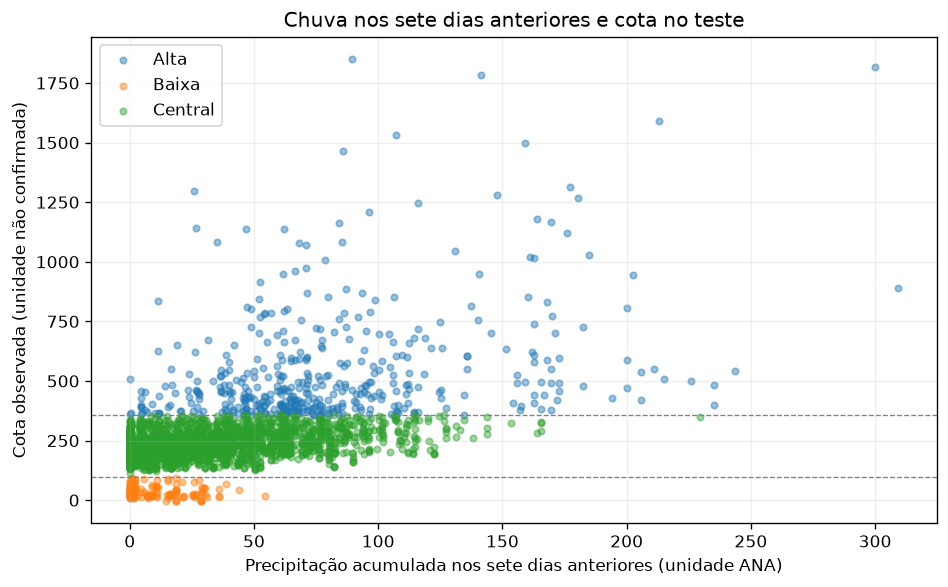

,Faixa,Amostras,MAE,RMSE
0,Alta (≥ P90 treino),435.0,113.650822,186.948085
1,Baixa (≤ P10 treino),151.0,26.933567,31.651349
2,Central,3065.0,20.795271,33.575890


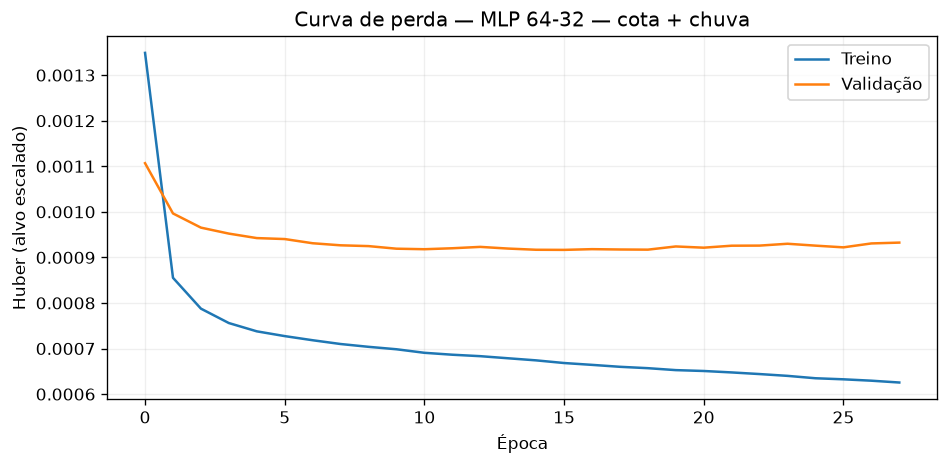

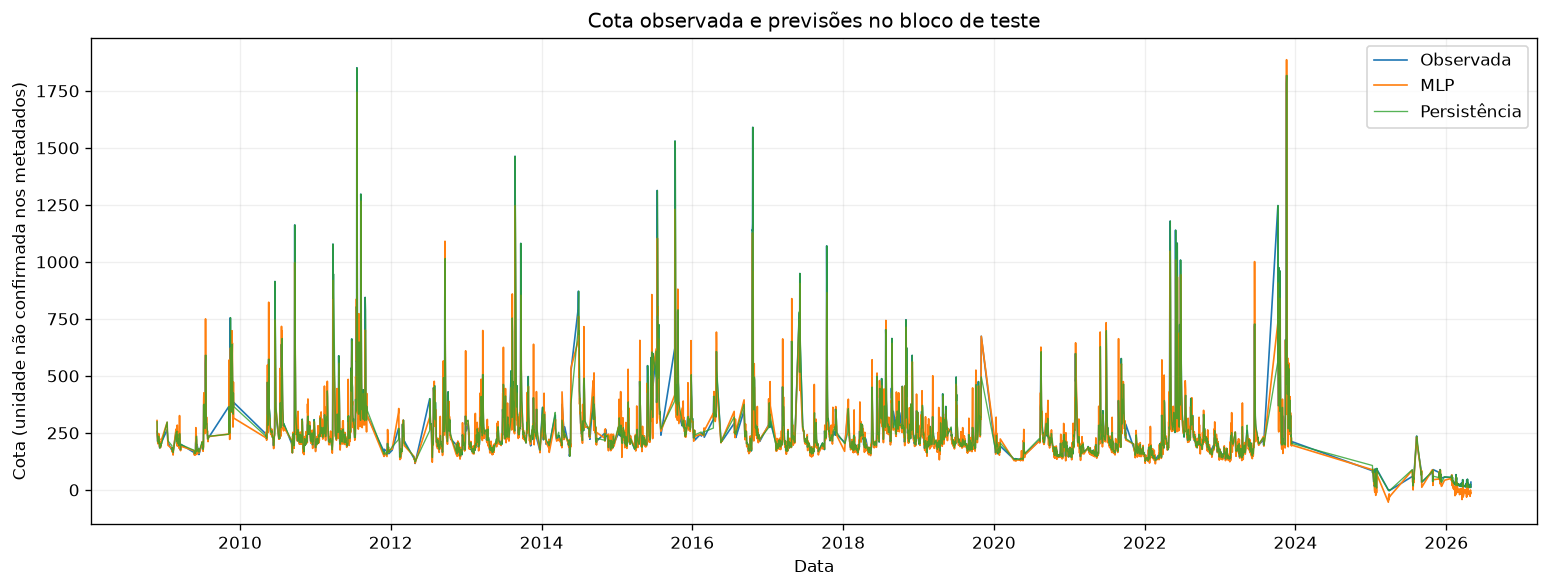

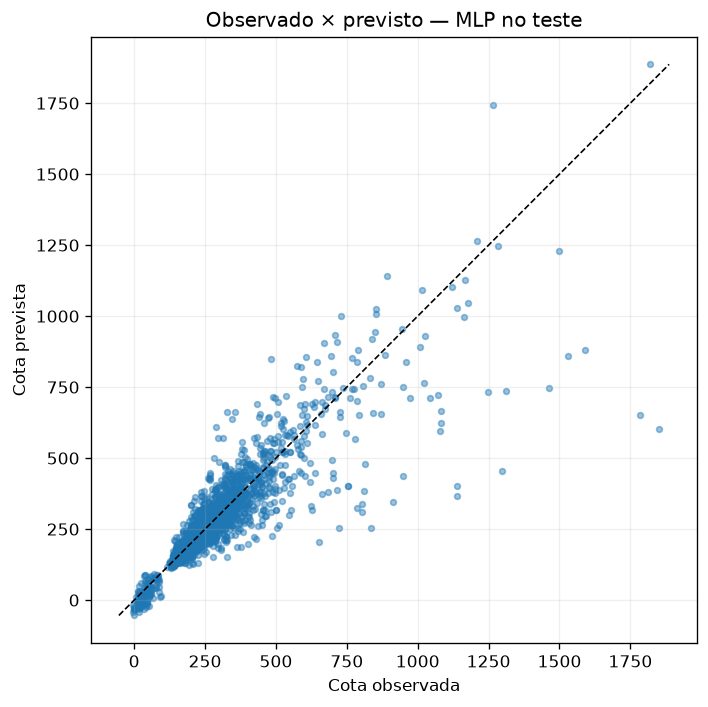

In [8]:
limite_baixo, limite_alto = treino[y_coluna].quantile([0.10, 0.90])
erro = pred_mlp - y_teste_real
# Chuva acumulada nos sete dias anteriores a cada cota-alvo de teste (t-7 a t-1).
chuva_7d_antecedente = diaria["Chuva"].rolling(window=7, min_periods=7).sum().shift(1)
alvos_teste = pd.DataFrame({
    "Data": pd.to_datetime(teste["data_alvo"].values),
    "Cota observada": y_teste_real,
})
alvos_teste["Chuva acumulada nos 7 dias anteriores"] = alvos_teste["Data"].map(chuva_7d_antecedente)
alvos_teste["Faixa"] = np.select(
    [alvos_teste["Cota observada"] <= limite_baixo,
     alvos_teste["Cota observada"] >= limite_alto],
    ["Baixa", "Alta"], default="Central"
)
resumo_antecedentes = alvos_teste.groupby("Faixa", observed=True).agg(
    Dias_testados=("Cota observada", "size"),
    Dias_com_chuva_completa=("Chuva acumulada nos 7 dias anteriores", "count"),
    Chuva_7d_mediana=("Chuva acumulada nos 7 dias anteriores", "median"),
    Chuva_7d_media=("Chuva acumulada nos 7 dias anteriores", "mean"),
).reset_index()
display(resumo_antecedentes)
resumo_antecedentes.to_csv(DIR_RESULTADOS / "antecedentes_chuva_niveis.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 5))
for nome, grupo in alvos_teste.groupby("Faixa", observed=True):
    ax.scatter(grupo["Chuva acumulada nos 7 dias anteriores"], grupo["Cota observada"],
               s=15, alpha=0.45, label=nome)
ax.axhline(limite_baixo, linestyle="--", linewidth=0.8, color="gray")
ax.axhline(limite_alto, linestyle="--", linewidth=0.8, color="gray")
ax.set(title="Chuva nos sete dias anteriores e cota no teste",
       xlabel="Precipitação acumulada nos sete dias anteriores (unidade ANA)",
       ylabel="Cota observada (unidade não confirmada)")
ax.grid(alpha=0.2); ax.legend(); fig.tight_layout()
fig.savefig(DIR_RESULTADOS / "chuva_antecedente_niveis.png", dpi=160, bbox_inches="tight")
plt.show()

faixa = np.select([y_teste_real <= limite_baixo, y_teste_real >= limite_alto],
                  ["Baixa (≤ P10 treino)", "Alta (≥ P90 treino)"], default="Central")
residuos = pd.DataFrame({"Real": y_teste_real, "Previsto": pred_mlp, "Erro": erro, "Faixa": faixa})
resumo_faixas = residuos.groupby("Faixa", observed=True).apply(
    lambda g: pd.Series({"Amostras": len(g), "MAE": np.mean(np.abs(g.Erro)),
                         "RMSE": np.sqrt(np.mean(g.Erro ** 2))}), include_groups=False
).reset_index()
display(resumo_faixas)
resumo_faixas.to_csv(DIR_RESULTADOS / "erros_por_faixa.csv", index=False)

historia_escolhida = escolhido["historia"]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(historia_escolhida["loss"], label="Treino")
ax.plot(historia_escolhida["val_loss"], label="Validação")
ax.set(title=f"Curva de perda — {escolhido['nome']}", xlabel="Época", ylabel="Huber (alvo escalado)")
ax.grid(alpha=0.2); ax.legend(); fig.tight_layout()
fig.savefig(DIR_RESULTADOS / "curva_aprendizado.png", dpi=160, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(teste["data_alvo"], y_teste_real, label="Observada", linewidth=1.0)
ax.plot(teste["data_alvo"], pred_mlp, label="MLP", linewidth=1.0)
ax.plot(teste["data_alvo"], pred_persistencia, label="Persistência", linewidth=0.8, alpha=0.8)
ax.set(title="Cota observada e previsões no bloco de teste", xlabel="Data", ylabel="Cota (unidade não confirmada nos metadados)")
ax.grid(alpha=0.2); ax.legend(); fig.tight_layout()
fig.savefig(DIR_RESULTADOS / "observado_previsto_teste.png", dpi=160, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_teste_real, pred_mlp, s=12, alpha=0.45)
limites = [min(y_teste_real.min(), pred_mlp.min()), max(y_teste_real.max(), pred_mlp.max())]
ax.plot(limites, limites, "--", color="black", linewidth=1)
ax.set(title="Observado × previsto — MLP no teste", xlabel="Cota observada", ylabel="Cota prevista")
ax.grid(alpha=0.2); fig.tight_layout()
fig.savefig(DIR_RESULTADOS / "dispersao_teste.png", dpi=160, bbox_inches="tight")
plt.show()

print(f"Limites estatísticos definidos no treino: P10={limite_baixo:.3f}, P90={limite_alto:.3f}")
print("Os limites não são cotas oficiais de alerta.")


## 9. Conclusão orientada pelos resultados

O texto abaixo é preenchido pelos resultados calculados nesta execução. Interprete o desempenho no contexto dos períodos usados e das limitações de cobertura, qualidade e representatividade espacial das chuvas. Não extrapole os resultados para alerta operacional ou para outros rios/reservatórios.


In [9]:
mae_persistencia = metricas.loc[metricas["Modelo"] == "Persistência", "MAE"].iloc[0]
mae_mlp = metricas.loc[metricas["Modelo"] == escolhido["nome"], "MAE"].iloc[0]
relacao = "superou" if mae_mlp < mae_persistencia else "não superou"
print(f"A configuração selecionada na validação foi {escolhido['nome']}.")
print(f"No bloco de teste, sua MAE foi {mae_mlp:.4f}; a persistência teve MAE {mae_persistencia:.4f}.")
print(f"Nesta divisão temporal, a MLP {relacao} a persistência em MAE.")
print(f"A conclusão se baseia em {len(teste):,} alvos de teste entre {teste['data_alvo'].min():%Y-%m-%d} e {teste['data_alvo'].max():%Y-%m-%d}.")
print("Consulte metricas_teste.csv, selecao_modelos_validacao.csv e as figuras em resultados/.")


A configuração selecionada na validação foi MLP 64-32 — cota + chuva.
No bloco de teste, sua MAE foi 32.1125; a persistência teve MAE 32.8422.
Nesta divisão temporal, a MLP superou a persistência em MAE.
A conclusão se baseia em 3,651 alvos de teste entre 2008-11-25 e 2026-04-30.
Consulte metricas_teste.csv, selecao_modelos_validacao.csv e as figuras em resultados/.


## 10. Roteiro da apresentação (5 minutos)

1. **Introdução (50 s):** problema, estações e número de janelas válidas.
2. **Metodologia (1 min 20 s):** limpeza, janela de sete dias, alvo `t+1`, divisão temporal e seleção pela validação.
3. **Resultados (1 min 40 s):** arquitetura escolhida, MAE/RMSE/R², persistência e figuras do teste.
4. **Conclusões (50 s):** desempenho observado, erros nas faixas baixa/alta, dificuldades e limitações.
5. **Capa/transições (20 s).**

Antes da apresentação, confirmar com o professor se exige execução especificamente no Colab e confirmar a unidade da cota nos metadados da estação.
